In [3]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class
from getdist.mcsamples import loadMCSamples

# 1. LOAD CHAINS
chains = loadMCSamples("../mavan_desy5/pngb_desy5")

# 2. SETTINGS
nsamples = 200   # Start small to test if it works, then increase to 200+
z_grid = np.linspace(0, 10, 200)
all_meff = []

# Use weights for statistical correctness
weights = chains.weights
indices = np.random.choice(len(weights), size=nsamples, p=weights/weights.sum())

print(f"Starting reconstruction for {nsamples} samples...")

# 3. LOOP
for k, idx in enumerate(indices):
    cosmo = Class()
    try:
        # Extract parameters
        p = lambda name: chains.samples[idx, chains.index[name]]
        
        params = {
            'omega_b': p('omega_b'),
            'omega_cdm': p('omega_cdm'),
            'H0': p('H0'),
            'A_s': p('A_s'),
            'n_s': p('n_s'),
            'N_ur': 0.044,
            'N_ncdm': 1,
            'm_ncdm': 0.06,
            'T_ncdm': 0.71611,
            'deg_ncdm': 3,
            'beta_ncdm': p('beta_ncdm'),
            'scf_parameters': f"{p('scf_lambda')}, -7, 0.0, 0.0, 1.0, 0.0",
            'Omega_fld': 0.0,
            'Omega_scf': -1,
            'Omega_Lambda': 0.0,
            'attractor_ic_scf': 'no',
            'scf_tuning_index': 1,
            'output': 'mPk',
            'P_k_max_1/Mpc': 1.0,
        }

        cosmo.set(params)
        cosmo.compute()

        bg = cosmo.get_background()
        
         # =========================
        # Background quantities
        # =========================
        z_bg = bg['z']
        phi_scf = bg['phi_scf']
        
        # sort in ascending z
        order = np.argsort(z_bg)
        
        z_sorted = z_bg[order]
        phi_sorted = phi_scf[order]
        
        beta_val = p('beta_ncdm')
        
        # present-day neutrino mass
        m0 = 0.06
        
        # phi today
        phi0 = phi_sorted[0]
        
        # effective neutrino mass
        m_eff = m0 * np.exp(
            beta_val * (phi_sorted - phi0)
        )
        
        # interpolate
        m_interp = np.interp(
            z_grid,
            z_sorted,
            m_eff
        )
        
        all_meff.append(m_interp)
        print(f"Success: {k+1}/{nsamples}", end="\r")

    except Exception as e:
        print(f"\nError at index {idx}: {e}")
    finally:
        cosmo.struct_cleanup()
        cosmo.empty()

# 4. STATISTICS & PLOTTING
if len(all_meff) == 0:
    print("Error: No successful CLASS runs. Check your parameter names and CLASS version.")
else:
    all_meff = np.array(all_meff)
    
    median = np.percentile(all_meff, 50, axis=0)
    low68, high68 = np.percentile(all_meff, [16, 84], axis=0)
    low95, high95 = np.percentile(all_meff, [2.5, 97.5], axis=0)


Starting reconstruction for 200 samples...


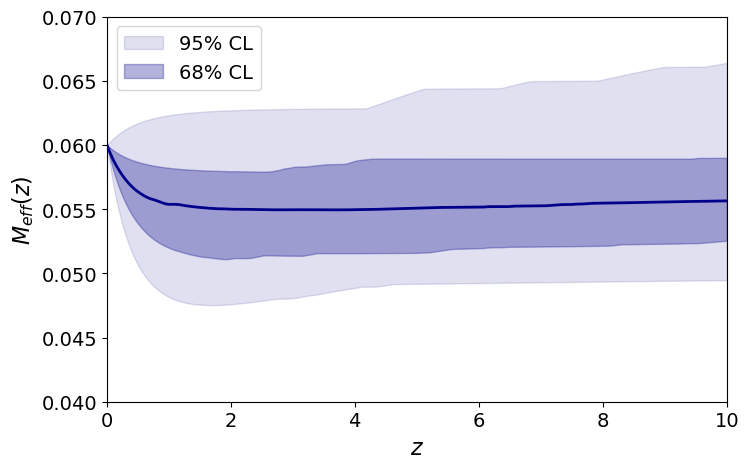

In [4]:
plt.figure(figsize=(8, 5))



plt.fill_between(
    z_grid,
    low95,
    high95,
    alpha=0.12,
    color='darkblue',
    label='95% CL'
)
plt.fill_between(
    z_grid,
    low68,
    high68,
    alpha=0.30,
    color='darkblue',
    label='68% CL'
)

plt.plot(
    z_grid,
    median,
    color='darkblue',
    lw=2,
)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel('$z$', fontsize=16)
plt.ylabel('$M_{eff}(z)$', fontsize=16)
plt.xlim(0, 10)
plt.ylim(0.04, 0.07)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=14)
plt.savefig('meff_data.pdf', bbox_inches='tight')
plt.show()